In [1]:
import numpy as np
import matplotlib.pyplot as plt
from plotly.subplots import make_subplots
import pandas as pd
import glob 
import os
import pickle
from pathlib import Path
import time
import pandas as pd

import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import pandas as pd
import glob 
import pywt #PyWavelets package
import matplotlib.colors as colors
from matplotlib.colors import LogNorm



from data_process import select_df,read_and_process_data ,fac_decompose_dB

In [2]:
with open(Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice-location-ready/"+"cassini_enis_2004_2017_60s.pkl"), "rb") as f:
    cassini_location = pickle.load(f)

In [6]:
with open(Path("/Users/chengzhimao/Documents/Code/saturn2025/data/spice-location-ready/"+"cassini_ksm_2004_2017_60s.pkl"), "rb") as f:
    cassini_location = pickle.load(f)

In [19]:
def merge_ICW_with_location(labels_df, cassini_location, tolerance='5min'):
    labels = labels_df.copy()
    loc = cassini_location.copy()

    labels['interval_start'] = pd.to_datetime(labels['interval_start']).dt.tz_localize(None)
    labels['interval_end'] = pd.to_datetime(labels['interval_end']).dt.tz_localize(None)
    loc['utc'] = pd.to_datetime(loc['utc']).dt.tz_localize(None)

    # Use interval midpoint as representative time
    labels['time'] = labels['interval_start'] + (
        labels['interval_end'] - labels['interval_start']
    ) / 2

    labels = labels.sort_values('time')
    loc = loc.sort_values('utc')

    # keep_cols = [
    #     'utc', 'x_ksm_Rs', 'y_ksm_Rs', 'z_ksm_Rs',
    #     'r_Rs', 'lat_deg', 'lon_deg'
    # ]
    # keep_cols = [c for c in keep_cols if c in loc.columns]

    merged = pd.merge_asof(
        labels,
        loc,
        left_on='time',
        right_on='utc',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance)
    )

    # return merged.dropna(subset=['r_Rs']).reset_index(drop=True)
    return merged.reset_index(drop=True)
    

# prep

## 1D

In [5]:
def one_d_occurrence_statistics(
    df,
    x_col,
    flag_col='is_ICW',
    bins=None,
    x_range=None,
    min_samples=1
):
    """
    Generic 1D occurrence statistics.

    Occurrence fraction = number of flagged intervals / total intervals in each bin.

    Returns columns:
        bin
        n_total
        n_wave
        x_mean
        occurrence_fraction
        occurrence_percent
    """

    d = df.dropna(subset=[x_col, flag_col]).copy()
    d[flag_col] = d[flag_col].astype(bool)

    if x_range is not None:
        d = d[
            (d[x_col] >= x_range[0]) &
            (d[x_col] <= x_range[1])
        ].copy()

    if bins is None:
        bins = np.linspace(d[x_col].min(), d[x_col].max(), 50)

    d['bin'] = pd.cut(d[x_col], bins=bins, include_lowest=True)

    stat = d.groupby('bin', observed=True).agg(
        n_total=(flag_col, 'size'),
        n_wave=(flag_col, 'sum'),
        x_mean=(x_col, 'mean')
    ).reset_index()

    stat['occurrence_fraction'] = stat['n_wave'] / stat['n_total']
    stat['occurrence_percent'] = 100 * stat['occurrence_fraction']

    stat.loc[
        stat['n_total'] < min_samples,
        ['occurrence_fraction', 'occurrence_percent']
    ] = np.nan

    return stat

In [6]:
def plot_one_d_occurrence(
    stat,
    x_label,
    title,
    y_mode='fraction',
    xlim=None,
    xticks=None,
    ax=None,
    marker='o'
):
    """
    Plot 1D occurrence rate from one_d_occurrence_statistics().
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    else:
        fig = ax.figure

    if y_mode == 'percent':
        y_col = 'occurrence_percent'
        y_label = 'ICW Occurrence Rate (%)'
    else:
        y_col = 'occurrence_fraction'
        y_label = 'ICW Fraction'

    ax.plot(
        stat['x_mean'],
        stat[y_col],
        marker=marker
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)

    if xlim is not None:
        ax.set_xlim(*xlim)

    if xticks is not None:
        ax.set_xticks(xticks)

    ax.grid(True, alpha=0.3)

    return fig, ax

In [7]:
def one_d_sample_statistics(
    df,
    x_col,
    bins=None,
    x_range=None,
    min_samples=1
):
    """
    Generic 1D sample-number statistics.

    Returns columns:
        bin
        n_total
        x_mean
    """

    d = df.dropna(subset=[x_col]).copy()

    if x_range is not None:
        d = d[
            (d[x_col] >= x_range[0]) &
            (d[x_col] <= x_range[1])
        ].copy()

    if bins is None:
        bins = np.linspace(d[x_col].min(), d[x_col].max(), 50)

    d['bin'] = pd.cut(d[x_col], bins=bins, include_lowest=True)

    stat = d.groupby('bin', observed=True).agg(
        n_total=(x_col, 'size'),
        x_mean=(x_col, 'mean')
    ).reset_index()

    stat.loc[stat['n_total'] < min_samples, 'n_total'] = np.nan

    return stat



In [8]:
def plot_one_d_samples(
    stat,
    x_label,
    title,
    xlim=None,
    xticks=None,
    ax=None,
    marker='o',
    log_y=False
):
    """
    Plot 1D sample numbers from one_d_sample_statistics().
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    else:
        fig = ax.figure

    ax.plot(
        stat['x_mean'],
        stat['n_total'],
        marker=marker
    )

    ax.set_xlabel(x_label)
    ax.set_ylabel('Number of Samples')
    ax.set_title(title)

    if log_y:
        ax.set_yscale('log')

    if xlim is not None:
        ax.set_xlim(*xlim)

    if xticks is not None:
        ax.set_xticks(xticks)

    ax.grid(True, alpha=0.3)

    return fig, ax

## 2D

In [9]:
def make_wave_occurrence_maps(
    df,
    L_col='L_approx',
    MLT_col='MLT_hr',
    MLAT_col='MLAT_approx_deg',
    flag_col='is_ICW',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.25,
    dMLT=0.5,
    dMLAT=2.5,
    min_samples=10
):
    """
    Make Long et al.-style occurrence maps:
        L-MLT:  dL x dMLT
        L-MLAT: dL x dMLAT

    Returns a dictionary containing occurrence maps and sample-number maps.
    """

    d = df.copy()

    needed = [L_col, MLT_col, MLAT_col, flag_col]
    missing = [c for c in needed if c not in d.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")

    d = d[needed].replace([np.inf, -np.inf], np.nan).dropna()
    d[flag_col] = d[flag_col].astype(bool)

    # Clean ranges
    d = d[
        (d[L_col] >= L_range[0]) &
        (d[L_col] <= L_range[1]) &
        (d[MLT_col] >= 0) &
        (d[MLT_col] < 24) &
        (d[MLAT_col] >= MLAT_range[0]) &
        (d[MLAT_col] <= MLAT_range[1])
    ].copy()

    L_edges = np.arange(L_range[0], L_range[1] + dL, dL)
    MLT_edges = np.arange(0, 24 + dMLT, dMLT)
    MLAT_edges = np.arange(MLAT_range[0], MLAT_range[1] + dMLAT, dMLAT)

    # -----------------------
    # L-MLT map
    # -----------------------
    total_L_MLT, _, _ = np.histogram2d(
        d[L_col],
        d[MLT_col],
        bins=[L_edges, MLT_edges]
    )

    wave_L_MLT, _, _ = np.histogram2d(
        d.loc[d[flag_col], L_col],
        d.loc[d[flag_col], MLT_col],
        bins=[L_edges, MLT_edges]
    )

    occ_L_MLT = 100.0 * wave_L_MLT / total_L_MLT
    occ_L_MLT[total_L_MLT < min_samples] = np.nan

    # -----------------------
    # L-MLAT map
    # -----------------------
    total_L_MLAT, _, _ = np.histogram2d(
        d[L_col],
        d[MLAT_col],
        bins=[L_edges, MLAT_edges]
    )

    wave_L_MLAT, _, _ = np.histogram2d(
        d.loc[d[flag_col], L_col],
        d.loc[d[flag_col], MLAT_col],
        bins=[L_edges, MLAT_edges]
    )

    occ_L_MLAT = 100.0 * wave_L_MLAT / total_L_MLAT
    occ_L_MLAT[total_L_MLAT < min_samples] = np.nan

    return {
        'L_edges': L_edges,
        'MLT_edges': MLT_edges,
        'MLAT_edges': MLAT_edges,

        'occ_L_MLT': occ_L_MLT,
        'Ns_L_MLT': total_L_MLT,

        'occ_L_MLAT': occ_L_MLAT,
        'Ns_L_MLAT': total_L_MLAT,

        'clean_df': d
    }

In [10]:
def plot_L_MLT_occurrence(maps, title='ICW Occurrence Rate in L-MLT'):
    L_edges = maps['L_edges']
    MLT_edges = maps['MLT_edges']
    occ = maps['occ_L_MLT']

    theta_edges = 2 * np.pi * MLT_edges / 24.0

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        occ,
        shading='auto',
        vmin=0,
        vmax=100
    )

    ax.set_theta_zero_location('E')   # 00 MLT on right
    ax.set_theta_direction(1)         # 06 top, 12 left, 18 bottom

    ax.set_xticks(2 * np.pi * np.array([0, 6, 12, 18]) / 24)
    ax.set_xticklabels(['00', '06', '12', '18'])

    ax.set_ylabel('L shell')
    ax.set_title(title)

    # Enceladus and Dione reference circles
    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, np.full_like(theta, 4.0), c='C3',linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), c='C1',linestyle='--', linewidth=1.5, label='Dione L~6.2')

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Occurrence Rate (%)')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.15))

    plt.show()

In [11]:
def plot_L_MLAT_occurrence(
    maps,
    title='ICW Occurrence Rate in L-MLAT',
    vmin=0,
    vmax=100
):
    L_edges = maps['L_edges']
    MLAT_edges = maps['MLAT_edges']
    occ = maps['occ_L_MLAT']

    theta_edges = np.radians(MLAT_edges)

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )


    
    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        occ,
        shading='auto',
        vmin=vmin,
        vmax=vmax
    )

    ax.set_thetamin(-90)
    ax.set_thetamax(90)

    # ax.set_theta_zero_location('W')
    # ax.set_theta_direction(-1)

    mlat_ticks = np.array([-60, -40, -20, 0, 20, 40, 60])
    theta_ticks = np.radians(mlat_ticks)

    ax.set_xticks(theta_ticks)
    ax.set_xticklabels([f'{x:g}°' for x in mlat_ticks])

    ax.set_xlabel('MLAT')
    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(-0.5*np.pi, 0.5*np.pi, 400)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Occurrence Rate (%)')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.1))

    plt.show()

In [12]:
def plot_L_MLT_samples(
    maps,
    title='Number of Samples in L-MLT',
    vmin=10,
    vmax=None
):
    L_edges = maps['L_edges']
    MLT_edges = maps['MLT_edges']
    Ns = maps['Ns_L_MLT'].copy()

    Ns[Ns < 1] = np.nan

    if vmax is None:
        vmax = np.nanmax(Ns)

    theta_edges = 2 * np.pi * MLT_edges / 24.0

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        Ns,
        shading='auto',
        norm=LogNorm(vmin=vmin, vmax=vmax)
    )

    ax.set_theta_zero_location('E')   # 00 MLT on right
    ax.set_theta_direction(1)         # 06 top, 12 left, 18 bottom

    ax.set_xticks(2 * np.pi * np.array([0, 6, 12, 18]) / 24)
    ax.set_xticklabels(['00', '06', '12', '18'])

    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Number of Samples')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.15))

    plt.show()

In [13]:
def plot_L_MLAT_samples(
    maps,
    title='Number of Samples in L-MLAT',
    vmin=10,
    vmax=None
):
    L_edges = maps['L_edges']
    MLAT_edges = maps['MLAT_edges']
    Ns = maps['Ns_L_MLAT'].copy()

    Ns[Ns < 1] = np.nan

    if vmax is None:
        vmax = np.nanmax(Ns)

    theta_edges = np.radians(MLAT_edges)

    fig, ax = plt.subplots(
        figsize=(7, 7),
        subplot_kw={'projection': 'polar'}
    )

    pcm = ax.pcolormesh(
        theta_edges,
        L_edges,
        Ns,
        shading='auto',
        norm=LogNorm(vmin=vmin, vmax=vmax)
    )

    ax.set_thetamin(-90)
    ax.set_thetamax(90)

    mlat_ticks = np.array([-60, -40, -20, 0, 20, 40, 60])
    theta_ticks = np.radians(mlat_ticks)

    ax.set_xticks(theta_ticks)
    ax.set_xticklabels([f'{x:g}°' for x in mlat_ticks])

    ax.set_xlabel('MLAT')
    ax.set_ylabel('L shell')
    ax.set_title(title)

    theta = np.linspace(-0.5 * np.pi, 0.5 * np.pi, 400)
    ax.plot(theta, np.full_like(theta, 4.0), linestyle='--', linewidth=1.5, label='Enceladus L~4')
    ax.plot(theta, np.full_like(theta, 6.2), linestyle='--', linewidth=1.5, label='Dione L~6.2')

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(pcm, ax=ax, pad=0.1)
    cbar.set_label('Number of Samples')

    ax.legend(loc='upper right', bbox_to_anchor=(1.85, 1.1))

    plt.show()

## 3D

In [14]:
def make_3d_occurrence_table(
    df,
    flag_col='is_ICW',
    L_col='L_approx',
    MLT_col='MLT_hr',
    MLAT_col='MLAT_approx_deg',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.25,
    dMLT=0.5,
    dMLAT=2.5,
    min_samples=10
):
    d = df[[L_col, MLT_col, MLAT_col, flag_col]].copy()
    d = d.replace([np.inf, -np.inf], np.nan).dropna()

    d[flag_col] = d[flag_col].astype(bool)

    d = d[
        (d[L_col] >= L_range[0]) &
        (d[L_col] <= L_range[1]) &
        (d[MLT_col] >= 0) &
        (d[MLT_col] < 24) &
        (d[MLAT_col] >= MLAT_range[0]) &
        (d[MLAT_col] <= MLAT_range[1])
    ].copy()

    L_edges = np.arange(L_range[0], L_range[1] + dL, dL)
    MLT_edges = np.arange(0, 24 + dMLT, dMLT)
    MLAT_edges = np.arange(MLAT_range[0], MLAT_range[1] + dMLAT, dMLAT)

    d['L_bin'] = pd.cut(d[L_col], bins=L_edges, include_lowest=True)
    d['MLT_bin'] = pd.cut(d[MLT_col], bins=MLT_edges, include_lowest=True)
    d['MLAT_bin'] = pd.cut(d[MLAT_col], bins=MLAT_edges, include_lowest=True)

    stat = d.groupby(
        ['L_bin', 'MLT_bin', 'MLAT_bin'],
        observed=True
    ).agg(
        n_total=(flag_col, 'size'),
        n_wave=(flag_col, 'sum'),
        L_mean=(L_col, 'mean'),
        MLT_mean=(MLT_col, 'mean'),
        MLAT_mean=(MLAT_col, 'mean')
    ).reset_index()

    stat['occurrence_fraction'] = stat['n_wave'] / stat['n_total']
    stat['occurrence_percent'] = 100 * stat['occurrence_fraction']

    stat = stat[stat['n_total'] >= min_samples].copy()

    theta = 2 * np.pi * stat['MLT_mean'] / 24.0
    mlat_rad = np.radians(stat['MLAT_mean'])

    # Simple magnetospheric 3D display coordinates
    stat['x'] = stat['L_mean'] * np.cos(theta)
    stat['y'] = stat['L_mean'] * np.sin(theta)
    stat['z'] = stat['L_mean'] * np.sin(mlat_rad)

    return stat

In [15]:
def plot_3d_occurrence_plotly_go(
    stat3d,
    color_col='occurrence_percent',
    title='3D ICW Occurrence Rate',
    color_range=(0, 100),
    marker_size=6,
    colorscale='Viridis',
    opacity=0.85
):
    """
    3D occurrence-rate plot using plotly.graph_objects.

    Marker size is fixed.
    Marker color shows occurrence rate.

    Required columns in stat3d:
        x, y, z
        L_mean, MLT_mean, MLAT_mean
        n_total, n_wave
        occurrence_percent
    """

    d = stat3d.copy()

    d = d.replace([np.inf, -np.inf], np.nan).dropna(
        subset=['x', 'y', 'z', color_col]
    )

    hover_text = [
        (
            f"L = {L:.2f}<br>"
            f"MLT = {MLT:.2f} hr<br>"
            f"MLAT = {MLAT:.1f}°<br>"
            f"N total = {Nt}<br>"
            f"N wave = {Nw}<br>"
            f"Occurrence = {Occ:.1f}%"
        )
        for L, MLT, MLAT, Nt, Nw, Occ in zip(
            d['L_mean'],
            d['MLT_mean'],
            d['MLAT_mean'],
            d['n_total'],
            d['n_wave'],
            d[color_col]
        )
    ]

    fig = go.Figure()

    fig.add_trace(
        go.Scatter3d(
            x=d['x'],
            y=d['y'],
            z=d['z'],
            mode='markers',
            text=hover_text,
            hoverinfo='text',
            marker=dict(
                size=marker_size,
                color=d[color_col],
                colorscale=colorscale,
                cmin=color_range[0],
                cmax=color_range[1],
                opacity=opacity,
                colorbar=dict(
                    title='Occurrence Rate (%)'
                )
            ),
            name='Occurrence'
        )
    )

    fig.update_layout(
        title=title,
        width=1500,
        height=600,
        scene=dict(
            xaxis=dict(title='X-like coordinate'),
            yaxis=dict(title='Y-like coordinate'),
            zaxis=dict(title='Z-like coordinate'),
            aspectmode='data'
        )
    )

    return fig

In [16]:
def add_L_shell_ring_go(
    fig,
    L=4.0,
    name='Enceladus L~4',
    z=0,
    line_width=5
):
    theta = np.linspace(0, 2 * np.pi, 500)

    x = L * np.cos(theta)
    y = L * np.sin(theta)
    zz = np.full_like(theta, z)

    fig.add_trace(
        go.Scatter3d(
            x=x,
            y=y,
            z=zz,
            mode='lines',
            name=name,
            line=dict(
                width=line_width,
                dash='dash'
            )
        )
    )

    return fig

#  ICW

In [20]:
with open('data/check_wave/ICW_labels_2004_2017.pkl', 'rb') as f:
    labels_df = pickle.load(f)

In [21]:
ICW_loc_df = merge_ICW_with_location(labels_df, cassini_location)
ICW_loc_df

,interval_start,interval_end,is_ICW,file_name,time,utc,et,x_enis_km,y_enis_km,z_enis_km,...,saturn_z_enis_km,saturn_x_enis_RE,saturn_y_enis_RE,saturn_z_enis_RE,sun_x_enis_km,sun_y_enis_km,sun_z_enis_km,sun_x_enis_RE,sun_y_enis_RE,sun_z_enis_RE
0,2004-05-14 00:10:24.500,2004-05-14 00:20:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:15:24.500,2004-05-14 00:15:00,1.377658e+08,-2.329855e+07,-6.010075e+06,-7.124432e+06,...,3.421951e-12,943.991689,-1.002338e-14,1.357953e-14,-7.836272e+07,-1.224916e+09,-5.674773e+08,-3.109714e+05,-4.860905e+06,-2.251954e+06
1,2004-05-14 00:20:24.500,2004-05-14 00:30:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:25:24.500,2004-05-14 00:25:00,1.377664e+08,-2.347501e+07,-5.256121e+06,-7.123562e+06,...,-1.776790e-12,944.130227,-1.192336e-14,-7.050940e-15,-1.173608e+08,-1.221787e+09,-5.674816e+08,-4.657297e+05,-4.848488e+06,-2.251971e+06
2,2004-05-14 00:30:24.500,2004-05-14 00:40:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:35:24.500,2004-05-14 00:35:00,1.377670e+08,-2.362729e+07,-4.497248e+06,-7.122686e+06,...,2.305288e-12,944.269236,-6.363557e-15,9.148209e-15,-1.562280e+08,-1.217418e+09,-5.674858e+08,-6.199687e+05,-4.831150e+06,-2.251988e+06
3,2004-05-14 00:40:24.500,2004-05-14 00:50:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:45:24.500,2004-05-14 00:45:00,1.377676e+08,-2.375526e+07,-3.734231e+06,-7.121804e+06,...,2.954970e-12,944.408574,-6.020744e-15,1.172638e-14,-1.949249e+08,-1.211814e+09,-5.674902e+08,-7.735321e+05,-4.808914e+06,-2.252005e+06
4,2004-05-14 00:50:24.500,2004-05-14 01:00:24.500,False,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,2004-05-14 00:55:24.500,2004-05-14 00:55:00,1.377682e+08,-2.385882e+07,-2.967851e+06,-7.120916e+06,...,2.813536e-12,944.548100,1.303487e-15,1.116512e-14,-2.334125e+08,-1.204983e+09,-5.674946e+08,-9.262646e+05,-4.781807e+06,-2.252022e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
665804,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:00:21.500,2017-08-31 23:00:00,5.574925e+08,-7.574319e+04,9.538960e+05,3.139608e+05,...,-3.257067e-13,940.335944,-5.380997e-15,-1.292521e-15,4.331465e+08,-1.273147e+09,6.761990e+08,1.718881e+06,-5.052303e+06,2.683401e+06
665805,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:10:21.500,2017-08-31 23:10:00,5.574931e+08,-4.486749e+04,9.611225e+05,3.143557e+05,...,2.243471e-12,940.382560,7.446328e-15,8.902896e-15,3.920245e+08,-1.286398e+09,6.761952e+08,1.555694e+06,-5.104891e+06,2.683385e+06
665806,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:20:21.500,2017-08-31 23:20:00,5.574937e+08,-1.384946e+04,9.673408e+05,3.147472e+05,...,2.323338e-13,940.433491,3.437544e-14,9.219839e-16,3.505024e+08,-1.298321e+09,6.761910e+08,1.390919e+06,-5.152205e+06,2.683369e+06
665807,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,2017-08-31 23:30:21.500,2017-08-31 23:30:00,5.574943e+08,1.727742e+04,9.725492e+05,3.151350e+05,...,1.395176e-12,940.488683,-5.592884e-16,5.536560e-15,3.086236e+08,-1.308903e+09,6.761866e+08,1.224729e+06,-5.194198e+06,2.683351e+06


In [22]:
# check how large in storage is the dataframe   ICW_loc_df
storage_bytes = ICW_loc_df.memory_usage(deep=True).sum()
storage_gb = storage_bytes / (1024 ** 3)
print(f"ICW_loc_df storage size: {storage_gb:.3f} GB")

ICW_loc_df storage size: 0.223 GB


## 1D

In [18]:
# Radial distance
r_bins = np.linspace(0, 20, 300)

r_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='r_Rs',
    flag_col='is_ICW',
    bins=r_bins,
    x_range=(0, 20),
    min_samples=1
)


# L shell
L_bins = np.linspace(0, 20, 300)

L_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='L_approx',
    flag_col='is_ICW',
    bins=L_bins,
    x_range=(0, 20),
    min_samples=1
)


# MLAT
MLAT_bins = np.arange(-90, 90 + 2.5, 2.5)

mlat_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='MLAT_approx_deg',
    flag_col='is_ICW',
    bins=MLAT_bins,
    x_range=(-90, 90),
    min_samples=1
)


# MLT
MLT_bins = np.arange(0, 24 + 0.5, 0.5)

mlt_stat = one_d_occurrence_statistics(
    ICW_loc_df,
    x_col='MLT_hr',
    flag_col='is_ICW',
    bins=MLT_bins,
    x_range=(0, 24),
    min_samples=10
)

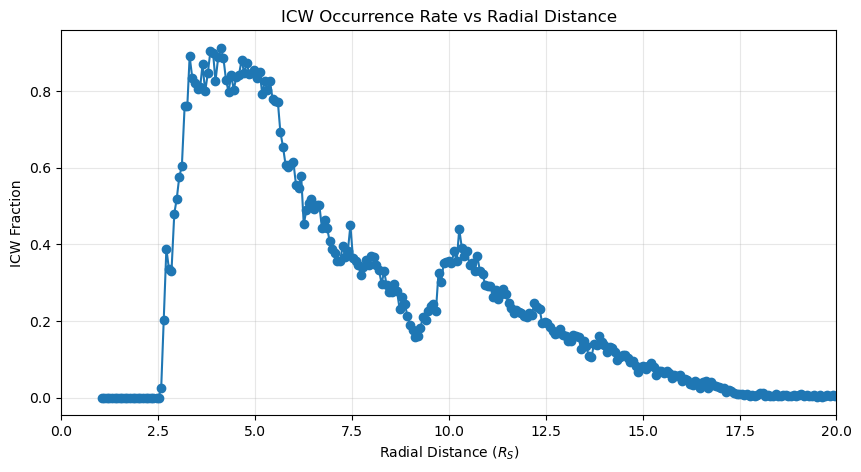

In [19]:
plot_one_d_occurrence(
    r_stat,
    x_label='Radial Distance ($R_S$)',
    title='ICW Occurrence Rate vs Radial Distance',
    y_mode='fraction',
    xlim=(0, 20)
)

plt.show()

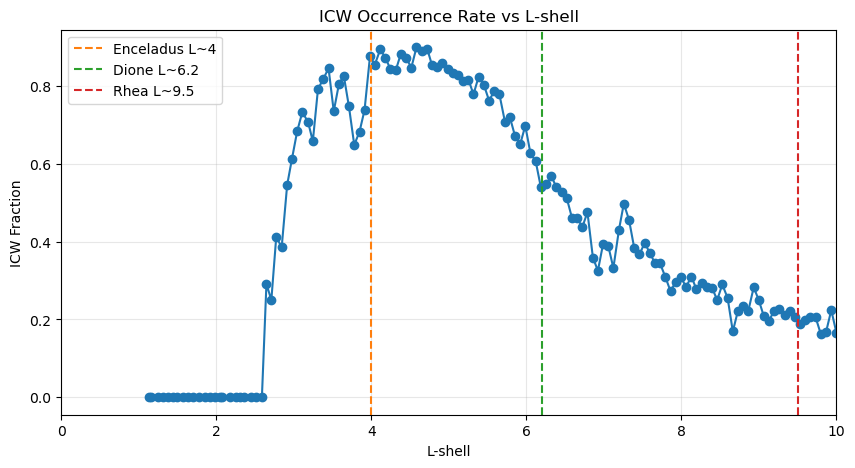

In [24]:
plot_one_d_occurrence(
    L_stat,
    x_label='L-shell',
    title='ICW Occurrence Rate vs L-shell',
    y_mode='fraction',
    xlim=(0, 10)
)

# add vertical lines for Enceladus, Dione, and Rhea
plt.axvline(4.0, color='C1', linestyle='--', label='Enceladus L~4')
plt.axvline(6.2, color='C2', linestyle='--', label='Dione L~6.2')
plt.axvline(9.5, color='C3', linestyle='--', label='Rhea L~9.5')
plt.legend()

plt.show()

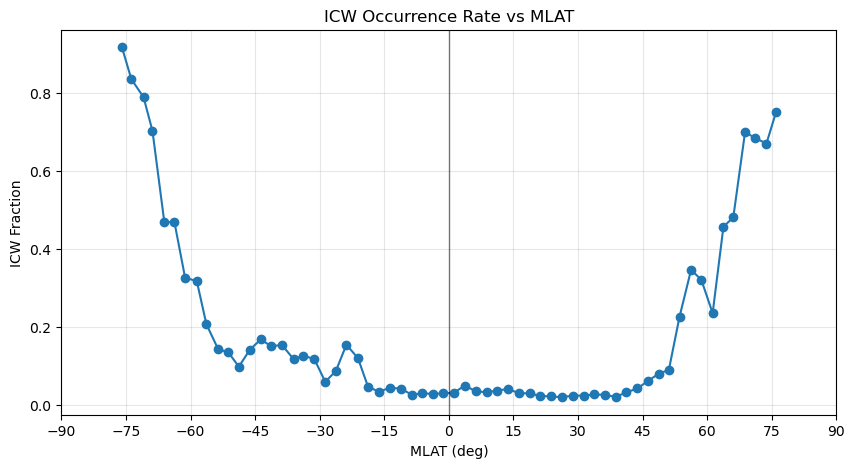

In [21]:
fig, ax = plot_one_d_occurrence(
    mlat_stat,
    x_label='MLAT (deg)',
    title='ICW Occurrence Rate vs MLAT',
    y_mode='fraction',
    xlim=(-90, 90),
    xticks=np.arange(-90, 91, 15)
)

ax.axvline(0, color='k', linewidth=1, alpha=0.5)

plt.show()

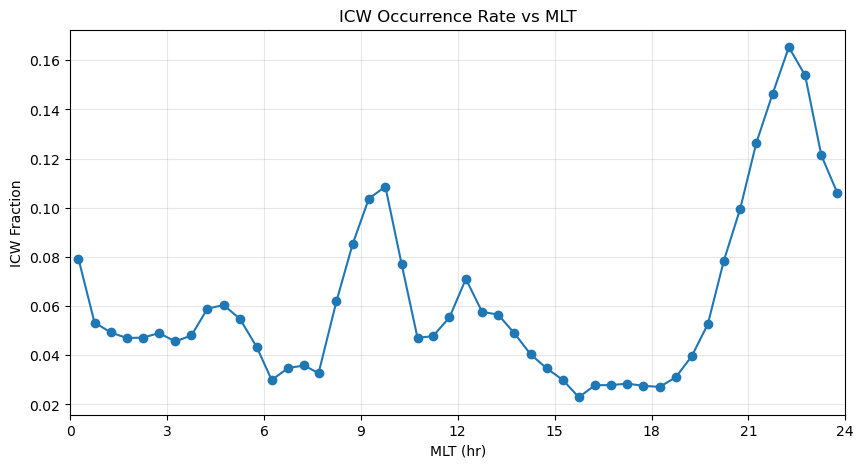

In [22]:
plot_one_d_occurrence(
    mlt_stat,
    x_label='MLT (hr)',
    title='ICW Occurrence Rate vs MLT',
    y_mode='fraction',
    xlim=(0, 24),
    xticks=np.arange(0, 25, 3)
)

plt.show()

## 1D sample

In [23]:
# Radial distance
r_bins = np.linspace(0, 20, 300)

r_sample_stat = one_d_sample_statistics(
    ICW_loc_df,
    x_col='r_Rs',
    bins=r_bins,
    x_range=(0, 20),
    min_samples=1
)


# L shell
L_bins = np.linspace(0, 20, 300)

L_sample_stat = one_d_sample_statistics(
    ICW_loc_df,
    x_col='L_approx',
    bins=L_bins,
    x_range=(0, 20),
    min_samples=1
)


# MLAT
MLAT_bins = np.arange(-90, 90 + 2.5, 2.5)

mlat_sample_stat = one_d_sample_statistics(
    ICW_loc_df,
    x_col='MLAT_approx_deg',
    bins=MLAT_bins,
    x_range=(-90, 90),
    min_samples=1
)


# MLT
MLT_bins = np.arange(0, 24 + 0.5, 0.5)

mlt_sample_stat = one_d_sample_statistics(
    ICW_loc_df,
    x_col='MLT_hr',
    bins=MLT_bins,
    x_range=(0, 24),
    min_samples=1
)

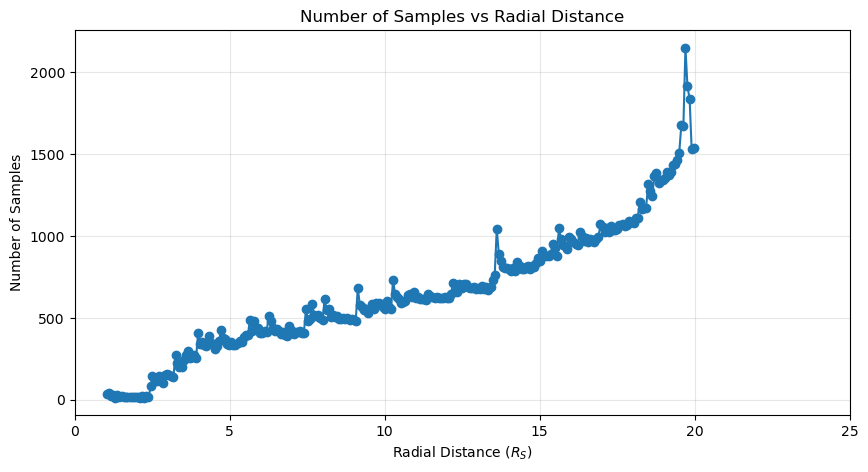

In [24]:
plot_one_d_samples(
    r_sample_stat,
    x_label='Radial Distance ($R_S$)',
    title='Number of Samples vs Radial Distance',
    xlim=(0, 25),
    log_y=False
)

plt.show()

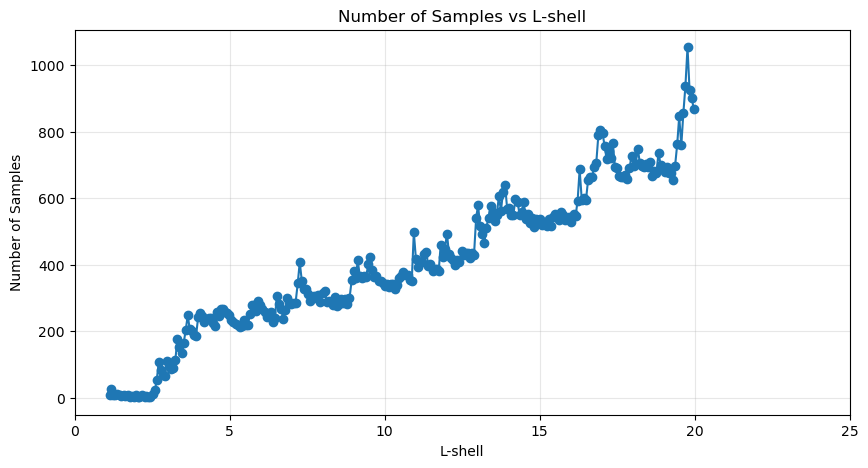

In [25]:
plot_one_d_samples(
    L_sample_stat,
    x_label='L-shell',
    title='Number of Samples vs L-shell',
    xlim=(0, 25),
    log_y=False
)

plt.show()

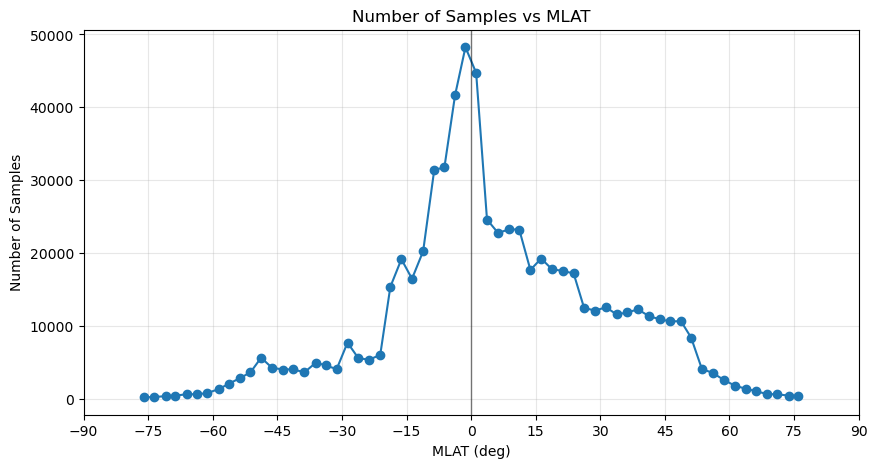

In [26]:
fig, ax = plot_one_d_samples(
    mlat_sample_stat,
    x_label='MLAT (deg)',
    title='Number of Samples vs MLAT',
    xlim=(-90, 90),
    xticks=np.arange(-90, 91, 15),
    log_y=False
)

ax.axvline(0, color='k', linewidth=1, alpha=0.5)

plt.show()

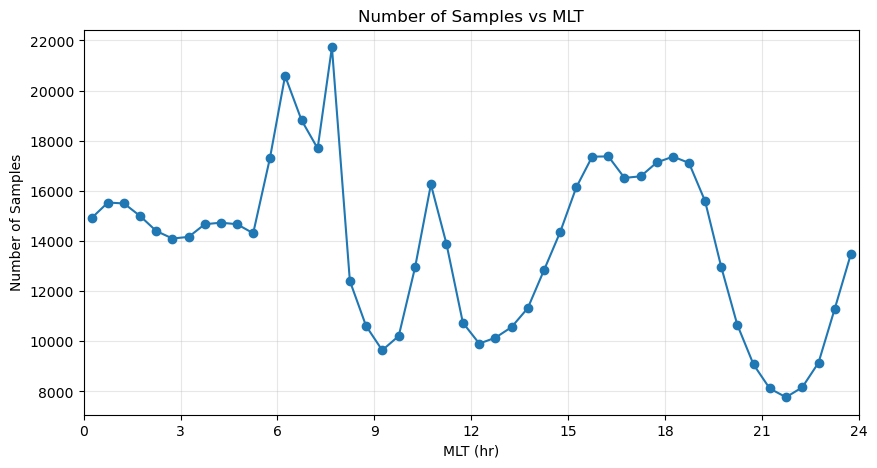

In [27]:
plot_one_d_samples(
    mlt_sample_stat,
    x_label='MLT (hr)',
    title='Number of Samples vs MLT',
    xlim=(0, 24),
    xticks=np.arange(0, 25, 3),
    log_y=False
)

plt.show()

## 2D 

In [49]:
maps = make_wave_occurrence_maps(
    ICW_loc_df,
    L_col='L_approx',
    MLT_col='MLT_hr',
    MLAT_col='MLAT_approx_deg',
    flag_col='is_ICW',
    L_range=(2, 12),
    MLAT_range=(-60, 60),
    dL=0.25,
    dMLT=0.5,
    dMLAT=2.5,
    min_samples=1
)

/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_59609/3849220026.py:61: RuntimeWarning: invalid value encountered in divide
  occ_L_MLT = 100.0 * wave_L_MLT / total_L_MLT
/var/folders/v_/4hys7cx12_q5gs6s1c9gqrvm0000gn/T/ipykernel_59609/3849220026.py:79: RuntimeWarning: invalid value encountered in divide
  occ_L_MLAT = 100.0 * wave_L_MLAT / total_L_MLAT


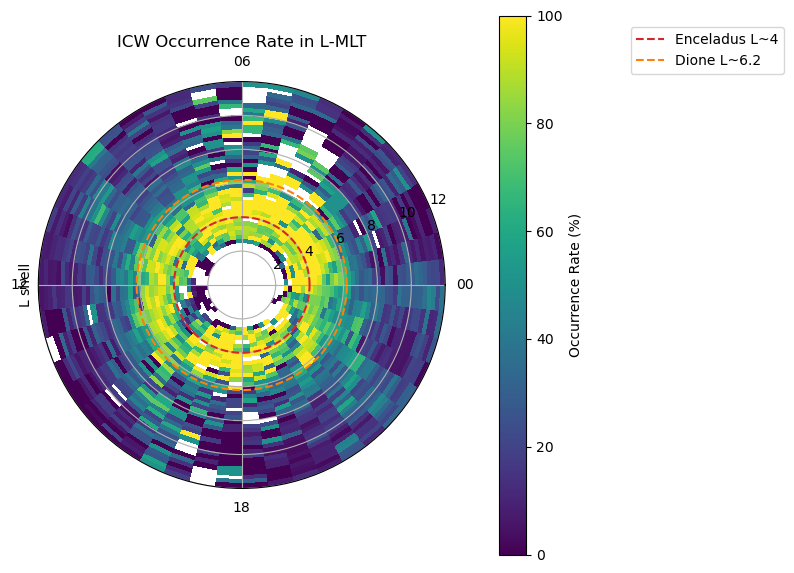

In [50]:
plot_L_MLT_occurrence(maps)

In [41]:
cassini_location

,utc,et,x_ksm_km,y_ksm_km,z_ksm_km,x_ksm_Rs,y_ksm_Rs,z_ksm_Rs,r_Rs,L_approx,MLT_hr,MLAT_approx_deg,vx_ksm_km_s,vy_ksm_km_s,vz_ksm_km_s,speed_km_s
0,2004-01-01 00:00:00+00:00,1.261873e+08,4.005082e+07,-7.727996e+07,-8.076749e+06,664.545415,-1282.271820,-134.013894,1450.448673,1462.937472,7.826382,-5.301392,-3.016327,4.156115,2.577700,5.745960
1,2004-01-01 00:01:00+00:00,1.261873e+08,4.005064e+07,-7.727971e+07,-8.076595e+06,664.542412,-1282.267682,-134.011330,1450.443402,1462.931765,7.826380,-5.301310,-3.016323,4.156638,2.572755,5.744119
2,2004-01-01 00:02:00+00:00,1.261874e+08,4.005046e+07,-7.727946e+07,-8.076441e+06,664.539410,-1282.263543,-134.008771,1450.438131,1462.926060,7.826378,-5.301228,-3.016318,4.157185,2.567579,5.742197
3,2004-01-01 00:03:00+00:00,1.261874e+08,4.005028e+07,-7.727921e+07,-8.076287e+06,664.536407,-1282.259404,-134.006218,1450.432860,1462.920355,7.826376,-5.301146,-3.016314,4.157756,2.562172,5.740193
4,2004-01-01 00:04:00+00:00,1.261875e+08,4.005010e+07,-7.727896e+07,-8.076133e+06,664.533404,-1282.255265,-134.003670,1450.427589,1462.914651,7.826374,-5.301064,-3.016310,4.158352,2.556535,5.738108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7209275,2017-09-15 10:35:00+00:00,5.587438e+08,5.393668e+04,-1.638833e+04,-2.235201e+04,0.894947,-0.271924,-0.370877,1.006192,1.164388,10.873261,-21.628962,-9.322713,15.323114,-25.094497,30.845495
7209276,2017-09-15 10:36:00+00:00,5.587438e+08,5.359939e+04,-1.557931e+04,-2.337360e+04,0.889351,-0.258501,-0.387828,1.004080,1.180147,10.919524,-22.721461,-1.985390,11.685418,-9.246031,15.032626
7209277,2017-09-15 10:37:00+00:00,5.587439e+08,5.357684e+04,-1.492657e+04,-2.371617e+04,0.888976,-0.247670,-0.393512,1.003230,1.185650,10.962140,-23.094249,0.567225,10.396320,-3.531702,10.994460
7209278,2017-09-15 10:38:00+00:00,5.587439e+08,5.363084e+04,-1.431399e+04,-2.387225e+04,0.889873,-0.237506,-0.396102,1.002586,1.188022,11.003746,-23.270963,1.108761,10.083740,-1.934777,10.327368


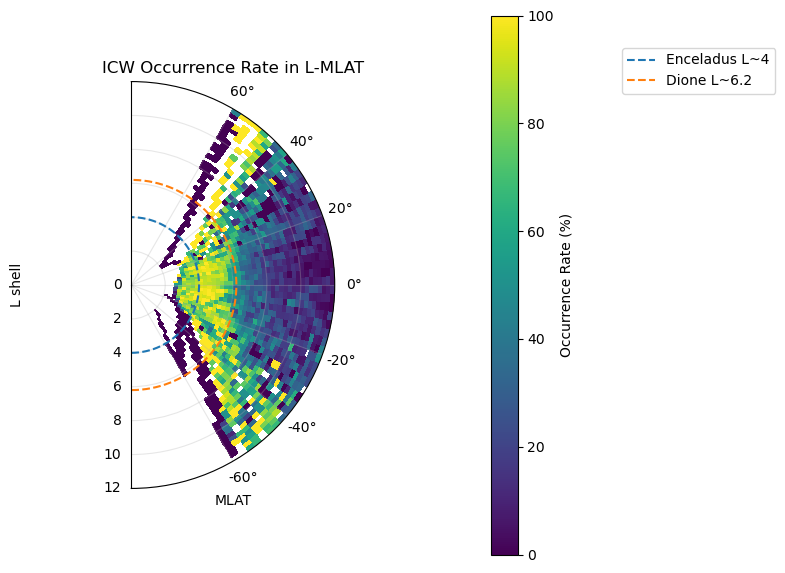

In [42]:
plot_L_MLAT_occurrence(maps)

## 2d sample

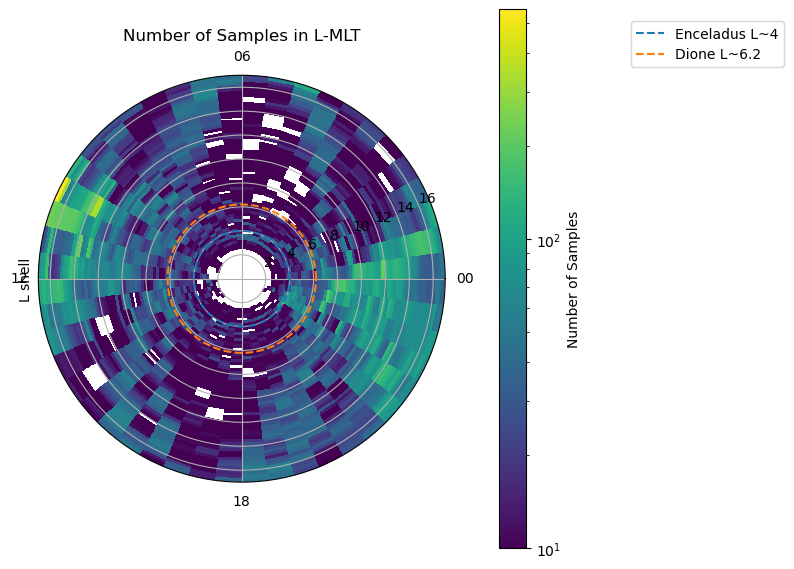

In [32]:
plot_L_MLT_samples(maps)

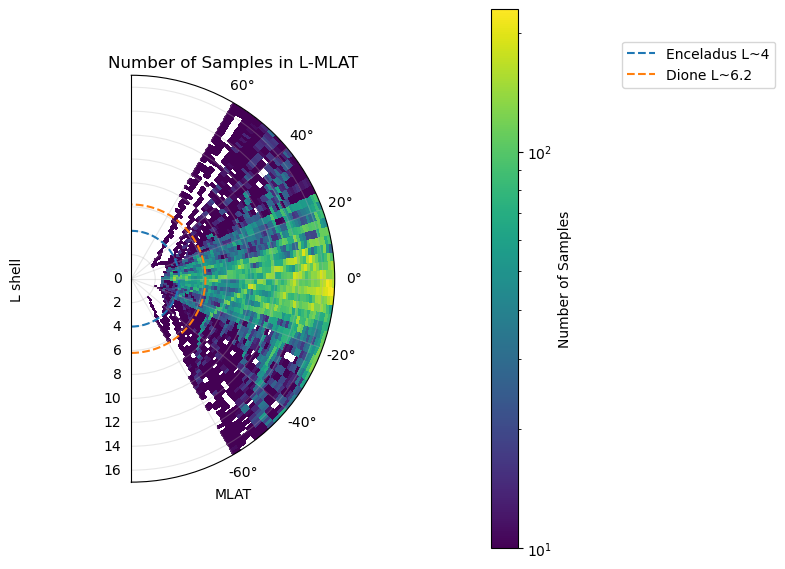

In [33]:
plot_L_MLAT_samples(maps)

## 3d

In [19]:
stat3d = make_3d_occurrence_table(
    ICW_loc_df,
    flag_col='is_ICW',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.5,
    dMLT=1.0,
    dMLAT=5.0,
    min_samples=10
)

fig = plot_3d_occurrence_plotly_go(
    stat3d,
    color_range=(0, 100),
    marker_size=6
)

fig = add_L_shell_ring_go(fig, L=4.0, name='Enceladus L~4')
fig = add_L_shell_ring_go(fig, L=6.2, name='Dione L~6.2')

fig.show()
fig.write_html('ICW_3D_occurrence.html')


# Together

## load in 

In [20]:
# load in the df with wave check results with time 
with open('data/check_wave/ICW_mirror_labels_2004_2017.pkl', 'rb') as f:
    labels_df = pickle.load(f)

In [21]:
waves_loc_df= merge_ICW_with_location(labels_df, cassini_location)

In [22]:
waves_loc_df

,interval_start,interval_end,is_ICW,is_mirror,label,file_name,B0_nT,fc_Hz_H2Oplus,icw_f_peak_Hz,icw_f_peak_over_fc,...,y_ksm_Rs,z_ksm_Rs,r_Rs,L_approx,MLT_hr,MLAT_approx_deg,vx_ksm_km_s,vy_ksm_km_s,vz_ksm_km_s,speed_km_s
0,2004-07-01 00:10:00.500,2004-07-01 00:20:00.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,664.963930,0.567292,0.374376,0.659935,...,-0.584312,1.139460,3.130307,3.608434,11.229263,21.346603,-13.762642,15.451467,-1.170533,20.725064
1,2004-07-01 00:20:00.500,2004-07-01 00:30:00.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,777.296952,0.663126,0.374376,0.564563,...,-0.429913,1.126586,2.971986,3.470701,11.400436,22.275994,-14.379342,15.563503,-1.421756,21.236985
2,2004-07-01 00:30:00.500,2004-07-01 00:40:00.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,916.660681,0.782019,0.499168,0.638306,...,-0.274495,1.111018,2.813165,3.333031,11.593545,23.261941,-15.066197,15.654686,-1.713054,21.794358
3,2004-07-01 00:40:00.500,2004-07-01 00:50:00.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,1091.602839,0.931266,0.499168,0.536010,...,-0.118315,1.092316,2.654202,3.195396,11.813102,24.301750,-15.834059,15.714649,-2.053080,22.402740
4,2004-07-01 00:50:00.500,2004-07-01 01:00:00.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/04135_04240_00_...,1313.677714,1.120722,NaN,NaN,...,0.038248,1.069942,2.495599,3.057623,12.064803,25.387087,-16.695215,15.728618,-2.452686,23.068058
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
658981,2017-08-31 22:55:21.500,2017-08-31 23:05:21.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,9.626379,0.008212,0.006656,0.810426,...,0.184711,12.136473,17.451953,33.796193,23.943739,44.060861,3.624372,-1.054152,-1.087250,3.928030
658982,2017-08-31 23:05:21.500,2017-08-31 23:15:21.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,9.538837,0.008138,0.006656,0.817864,...,0.174215,12.125578,17.418297,33.796424,23.946782,44.118150,3.639168,-1.054416,-1.101628,3.945747
658983,2017-08-31 23:15:21.500,2017-08-31 23:25:21.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,9.483587,0.008091,0.004992,0.616972,...,0.163718,12.114538,17.384459,33.796538,23.949843,44.175642,3.654008,-1.054443,-1.116080,3.963491
658984,2017-08-31 23:25:21.500,2017-08-31 23:35:21.500,False,False,uncertain,data/_cassini-mag-cal-sec-krtp/17242_17248_291...,9.515213,0.008118,0.006656,0.819895,...,0.153221,12.103355,17.350437,33.796535,23.952921,44.233339,3.668891,-1.054236,-1.130606,3.981262


## 1D

### ICW

In [28]:
# Radial distance
r_bins = np.linspace(0, 30, 300)

r_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='r_Rs',
    flag_col='is_ICW',
    bins=r_bins,
    x_range=(0, 30),
    min_samples=1
)


# L shell
L_bins = np.linspace(0, 20, 300)

L_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='L_approx',
    flag_col='is_ICW',
    bins=L_bins,
    x_range=(0, 20),
    min_samples=1
)


# MLAT
MLAT_bins = np.arange(-90, 90 + 2.5, 2.5)

mlat_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='MLAT_approx_deg',
    flag_col='is_ICW',
    bins=MLAT_bins,
    x_range=(-90, 90),
    min_samples=1
)


# MLT
MLT_bins = np.arange(0, 24 + 0.5, 0.5)

mlt_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='MLT_hr',
    flag_col='is_ICW',
    bins=MLT_bins,
    x_range=(0, 24),
    min_samples=10
)

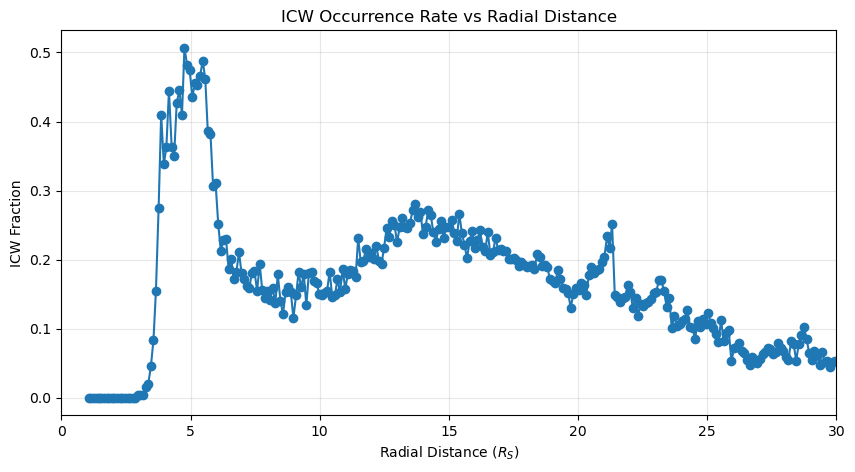

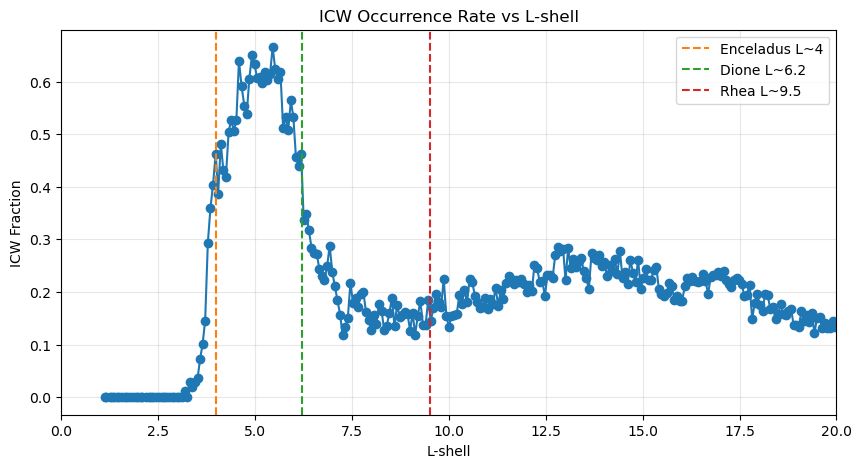

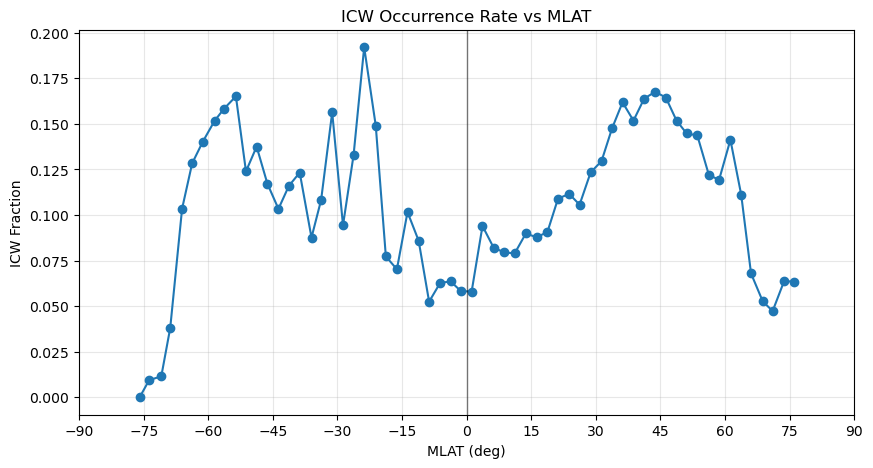

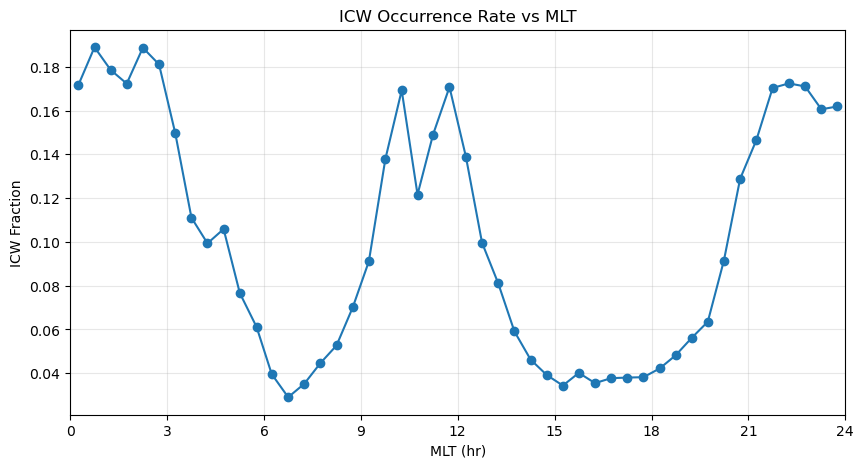

In [33]:
plot_one_d_occurrence(
    r_stat,
    x_label='Radial Distance ($R_S$)',
    title='ICW Occurrence Rate vs Radial Distance',
    y_mode='fraction',
    xlim=(0, 30)
)

plt.show()
plot_one_d_occurrence(
    L_stat,
    x_label='L-shell',
    title='ICW Occurrence Rate vs L-shell',
    y_mode='fraction',
    xlim=(0, 20)
)
# add the vertical lines for Enceladus, Dione, and Rhea
plt.axvline(4.0, color='C1', linestyle='--', label='Enceladus L~4')
plt.axvline(6.2, color='C2', linestyle='--', label='Dione L~6.2')
plt.axvline(9.5, color='C3', linestyle='--', label='Rhea L~9.5')
plt.legend()

plt.show()
fig, ax = plot_one_d_occurrence(
    mlat_stat,
    x_label='MLAT (deg)',
    title='ICW Occurrence Rate vs MLAT',
    y_mode='fraction',
    xlim=(-90, 90),
    xticks=np.arange(-90, 91, 15)
)

ax.axvline(0, color='k', linewidth=1, alpha=0.5)

plt.show()
plot_one_d_occurrence(
    mlt_stat,
    x_label='MLT (hr)',
    title='ICW Occurrence Rate vs MLT',
    y_mode='fraction',
    xlim=(0, 24),
    xticks=np.arange(0, 25, 3)
)

plt.show()

### mirror

In [34]:
# Radial distance
r_bins = np.linspace(0, 20, 300)

r_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='r_Rs',
    flag_col='is_mirror',
    bins=r_bins,
    x_range=(0, 20),
    min_samples=1
)


# L shell
L_bins = np.linspace(0, 20, 300)

L_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='L_approx',
    flag_col='is_mirror',
    bins=L_bins,
    x_range=(0, 20),
    min_samples=1
)


# MLAT
MLAT_bins = np.arange(-90, 90 + 2.5, 2.5)

mlat_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='MLAT_approx_deg',
    flag_col='is_mirror',
    bins=MLAT_bins,
    x_range=(-90, 90),
    min_samples=1
)


# MLT
MLT_bins = np.arange(0, 24 + 0.5, 0.5)

mlt_stat = one_d_occurrence_statistics(
    waves_loc_df,
    x_col='MLT_hr',
    flag_col='is_mirror',
    bins=MLT_bins,
    x_range=(0, 24),
    min_samples=10
)

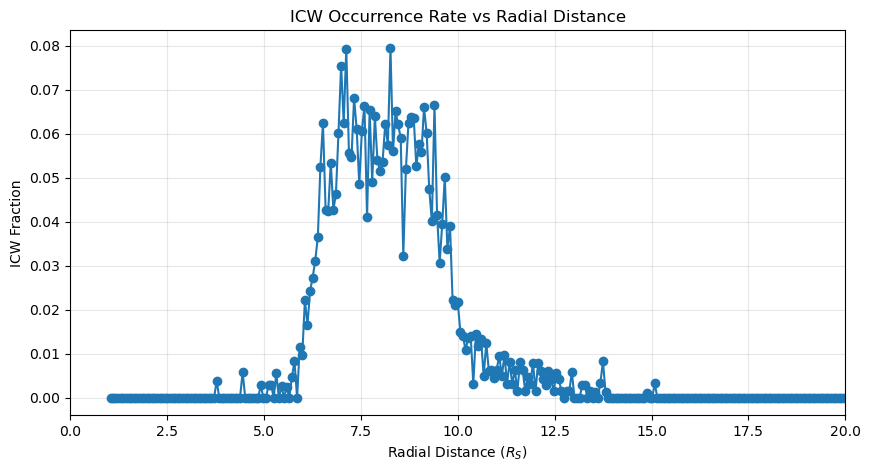

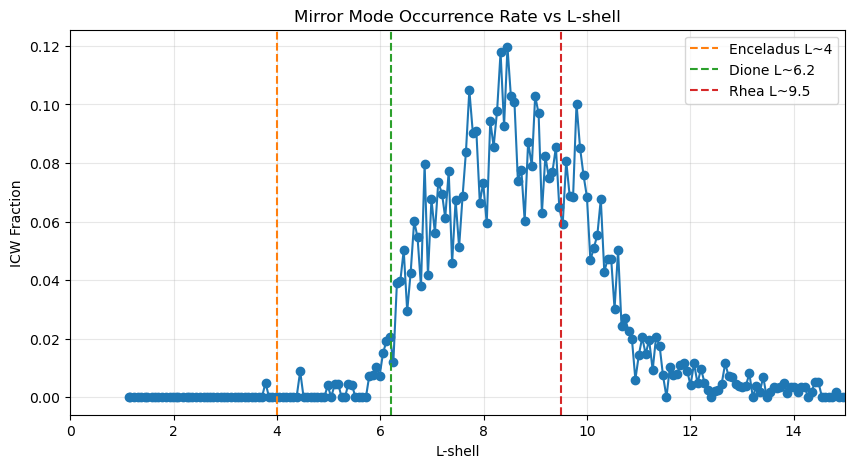

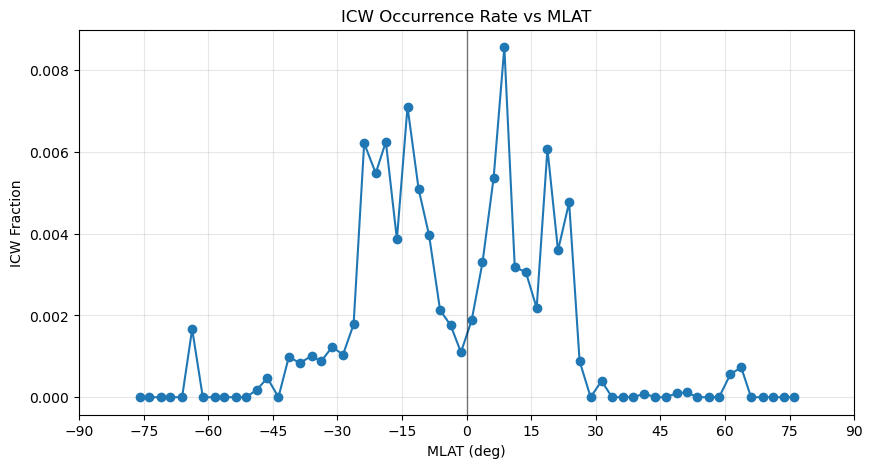

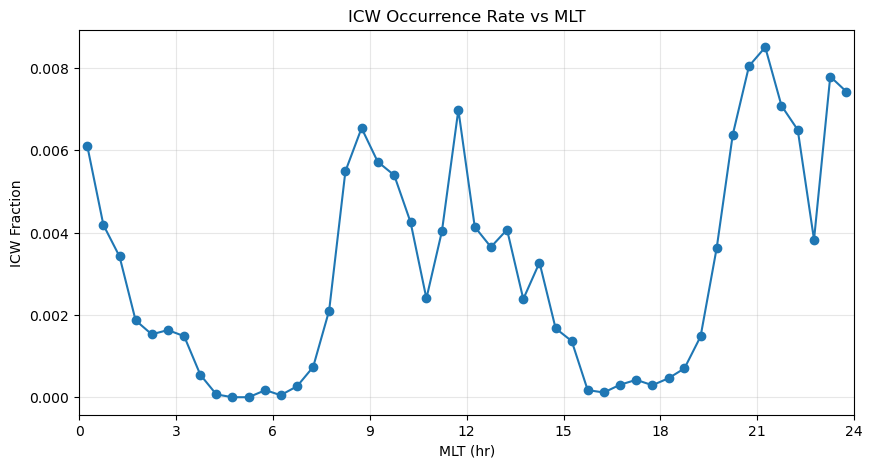

In [37]:
plot_one_d_occurrence(
    r_stat,
    x_label='Radial Distance ($R_S$)',
    title='ICW Occurrence Rate vs Radial Distance',
    y_mode='fraction',
    xlim=(0, 20)
)

plt.show()
plot_one_d_occurrence(
    L_stat,
    x_label='L-shell',
    title='Mirror Mode Occurrence Rate vs L-shell',
    y_mode='fraction',
    xlim=(0, 15)
)
# add the vertical lines for Enceladus, Dione, and Rhea
plt.axvline(4.0, color='C1', linestyle='--', label='Enceladus L~4')
plt.axvline(6.2, color='C2', linestyle='--', label='Dione L~6.2')
plt.axvline(9.5, color='C3', linestyle='--', label='Rhea L~9.5')
plt.legend()

plt.show()
fig, ax = plot_one_d_occurrence(
    mlat_stat,
    x_label='MLAT (deg)',
    title='ICW Occurrence Rate vs MLAT',
    y_mode='fraction',
    xlim=(-90, 90),
    xticks=np.arange(-90, 91, 15)
)

ax.axvline(0, color='k', linewidth=1, alpha=0.5)

plt.show()
plot_one_d_occurrence(
    mlt_stat,
    x_label='MLT (hr)',
    title='ICW Occurrence Rate vs MLT',
    y_mode='fraction',
    xlim=(0, 24),
    xticks=np.arange(0, 25, 3)
)

plt.show()

## 3d

### ICW

In [23]:
stat3d = make_3d_occurrence_table(
    waves_loc_df,
    flag_col='is_ICW',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.5,
    dMLT=1.0,
    dMLAT=5.0,
    min_samples=10
)

fig = plot_3d_occurrence_plotly_go(
    stat3d,
    title='Holistic 3D ICW Occurrence Rate',
    color_range=(0, 100),
    marker_size=6
)

fig = add_L_shell_ring_go(fig, L=4.0, name='Enceladus L~4')
fig = add_L_shell_ring_go(fig, L=6.2, name='Dione L~6.2')

fig.show()
fig.write_html('holistic_ICW_3D_occurrence.html')

### Mirror

In [24]:
stat3d = make_3d_occurrence_table(
    waves_loc_df,
    flag_col='is_mirror',
    L_range=(2, 20),
    MLAT_range=(-60, 60),
    dL=0.5,
    dMLT=1.0,
    dMLAT=5.0,
    min_samples=10
)

fig = plot_3d_occurrence_plotly_go(
    stat3d,
    title='Holistic 3D Mirror Occurrence Rate',
    color_range=(0, 30),
    marker_size=6
)

fig = add_L_shell_ring_go(fig, L=4.0, name='Enceladus L~4')
fig = add_L_shell_ring_go(fig, L=6.2, name='Dione L~6.2')

fig.show()
fig.write_html('holistic_Mirror_3D_occurrence.html')